# Train / Validation / Test Split

This notebook is the seventh step in the pipeline, following feature engineering and categorical encoding. Its purpose is to split the fully prepared dataset into three disjoint subsets: **training**, **validation**, and **test**.

**Why a three-way split?** In a typical ML workflow, each subset has a distinct role:

- **Training set (80%)** — Used to fit the model's parameters (weights, coefficients, tree splits, etc.).
- **Validation set (10%)** — Used during model development to tune hyperparameters, compare candidate models, and make early-stopping decisions. The model never directly learns from this data, but we use its performance to guide our choices.
- **Test set (10%)** — Held out completely until the very end. It provides an unbiased estimate of how the final, chosen model will perform on new, unseen data. It must never influence any decision during training or tuning.

Before splitting, we perform two important preparatory steps: dropping irrelevant columns and checking for highly correlated features that could introduce multicollinearity.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split


In [2]:
df = pd.read_csv('spitogatos_encode.csv')
df.head()


,listingId,airConditioning,alarm,areaSqm,balcony,bathrooms,closedParkingSpots,elevator,energyClass,fireplace,...,yearBuilt,locationFloor,totalParkingSpots,apartmentAge,district,is_renovated,rooms_area,bath_area,floor_elevator,floor_view
0,20304396,1,0,3.850148,0,1.0,0.0,1,4,0,...,1975.0,Κέντρο Θεσσαλονίκης,0.0,51.0,1.0,1,3.850148,3.850148,7,7
1,19956518,1,0,3.218876,0,1.0,0.0,1,3,0,...,1982.0,Κέντρο Θεσσαλονίκης,0.0,44.0,1.0,1,3.218876,3.218876,8,8
2,18383741,0,0,4.094345,0,1.0,0.0,1,5,0,...,1978.0,Ανάληψη - Μπότσαρη - Νέα Παραλία,0.0,48.0,5.0,0,4.094345,4.094345,6,6
3,20242029,1,0,4.094345,0,1.0,0.0,1,7,0,...,1978.0,Ανάληψη - Μπότσαρη - Νέα Παραλία,0.0,48.0,5.0,0,4.094345,4.094345,8,8
4,20055845,1,0,4.317488,0,1.0,0.0,1,4,0,...,1981.0,Τούμπα,0.0,45.0,4.0,0,8.634976,4.317488,4,4


## Dropping Irrelevant Columns

Not every column in the dataset is useful (or appropriate) as a model input. We drop the following:

- `listingId` — A unique identifier for each listing. IDs carry no predictive signal and would only confuse the model.
- `listingType` and `propertyType` — These columns are constant (all entries are apartment rentals), so they provide zero variance and no discriminative power.
- `pricePerSqm` — This is a **derived target** (price / areaSqm). Including it as a predictor would be a form of **data leakage**, because it is directly computed from the target variable (`price`). The model would trivially learn to rely on it, producing inflated performance metrics that do not generalise to real-world usage where `price` is unknown.
- `location` — The raw composite string (e.g., `Antigonidon (Centre)`). We already extracted the district from this column in the feature engineering step.
- `locationFloor` — The 12-category municipal district. We already mapped this to the 5-district numeric encoding, so this intermediate column is no longer needed.


In [3]:
df = df.drop(['listingId', 'listingType', 'propertyType', 'pricePerSqm', 'location', 'locationFloor'], axis=1)


## Multicollinearity Check

Before splitting, we revisit the **Spearman correlation matrix** one final time. Feature engineering and encoding may have introduced new correlations (e.g., between interaction features and their parent features). High correlation between predictors, known as **multicollinearity**, is problematic for linear models because it inflates the variance of coefficient estimates, making them unstable and hard to interpret.

We exclude `pool` from the heatmap because it contains only a single unique value (all apartments lack a pool), making its correlation undefined (NaN).


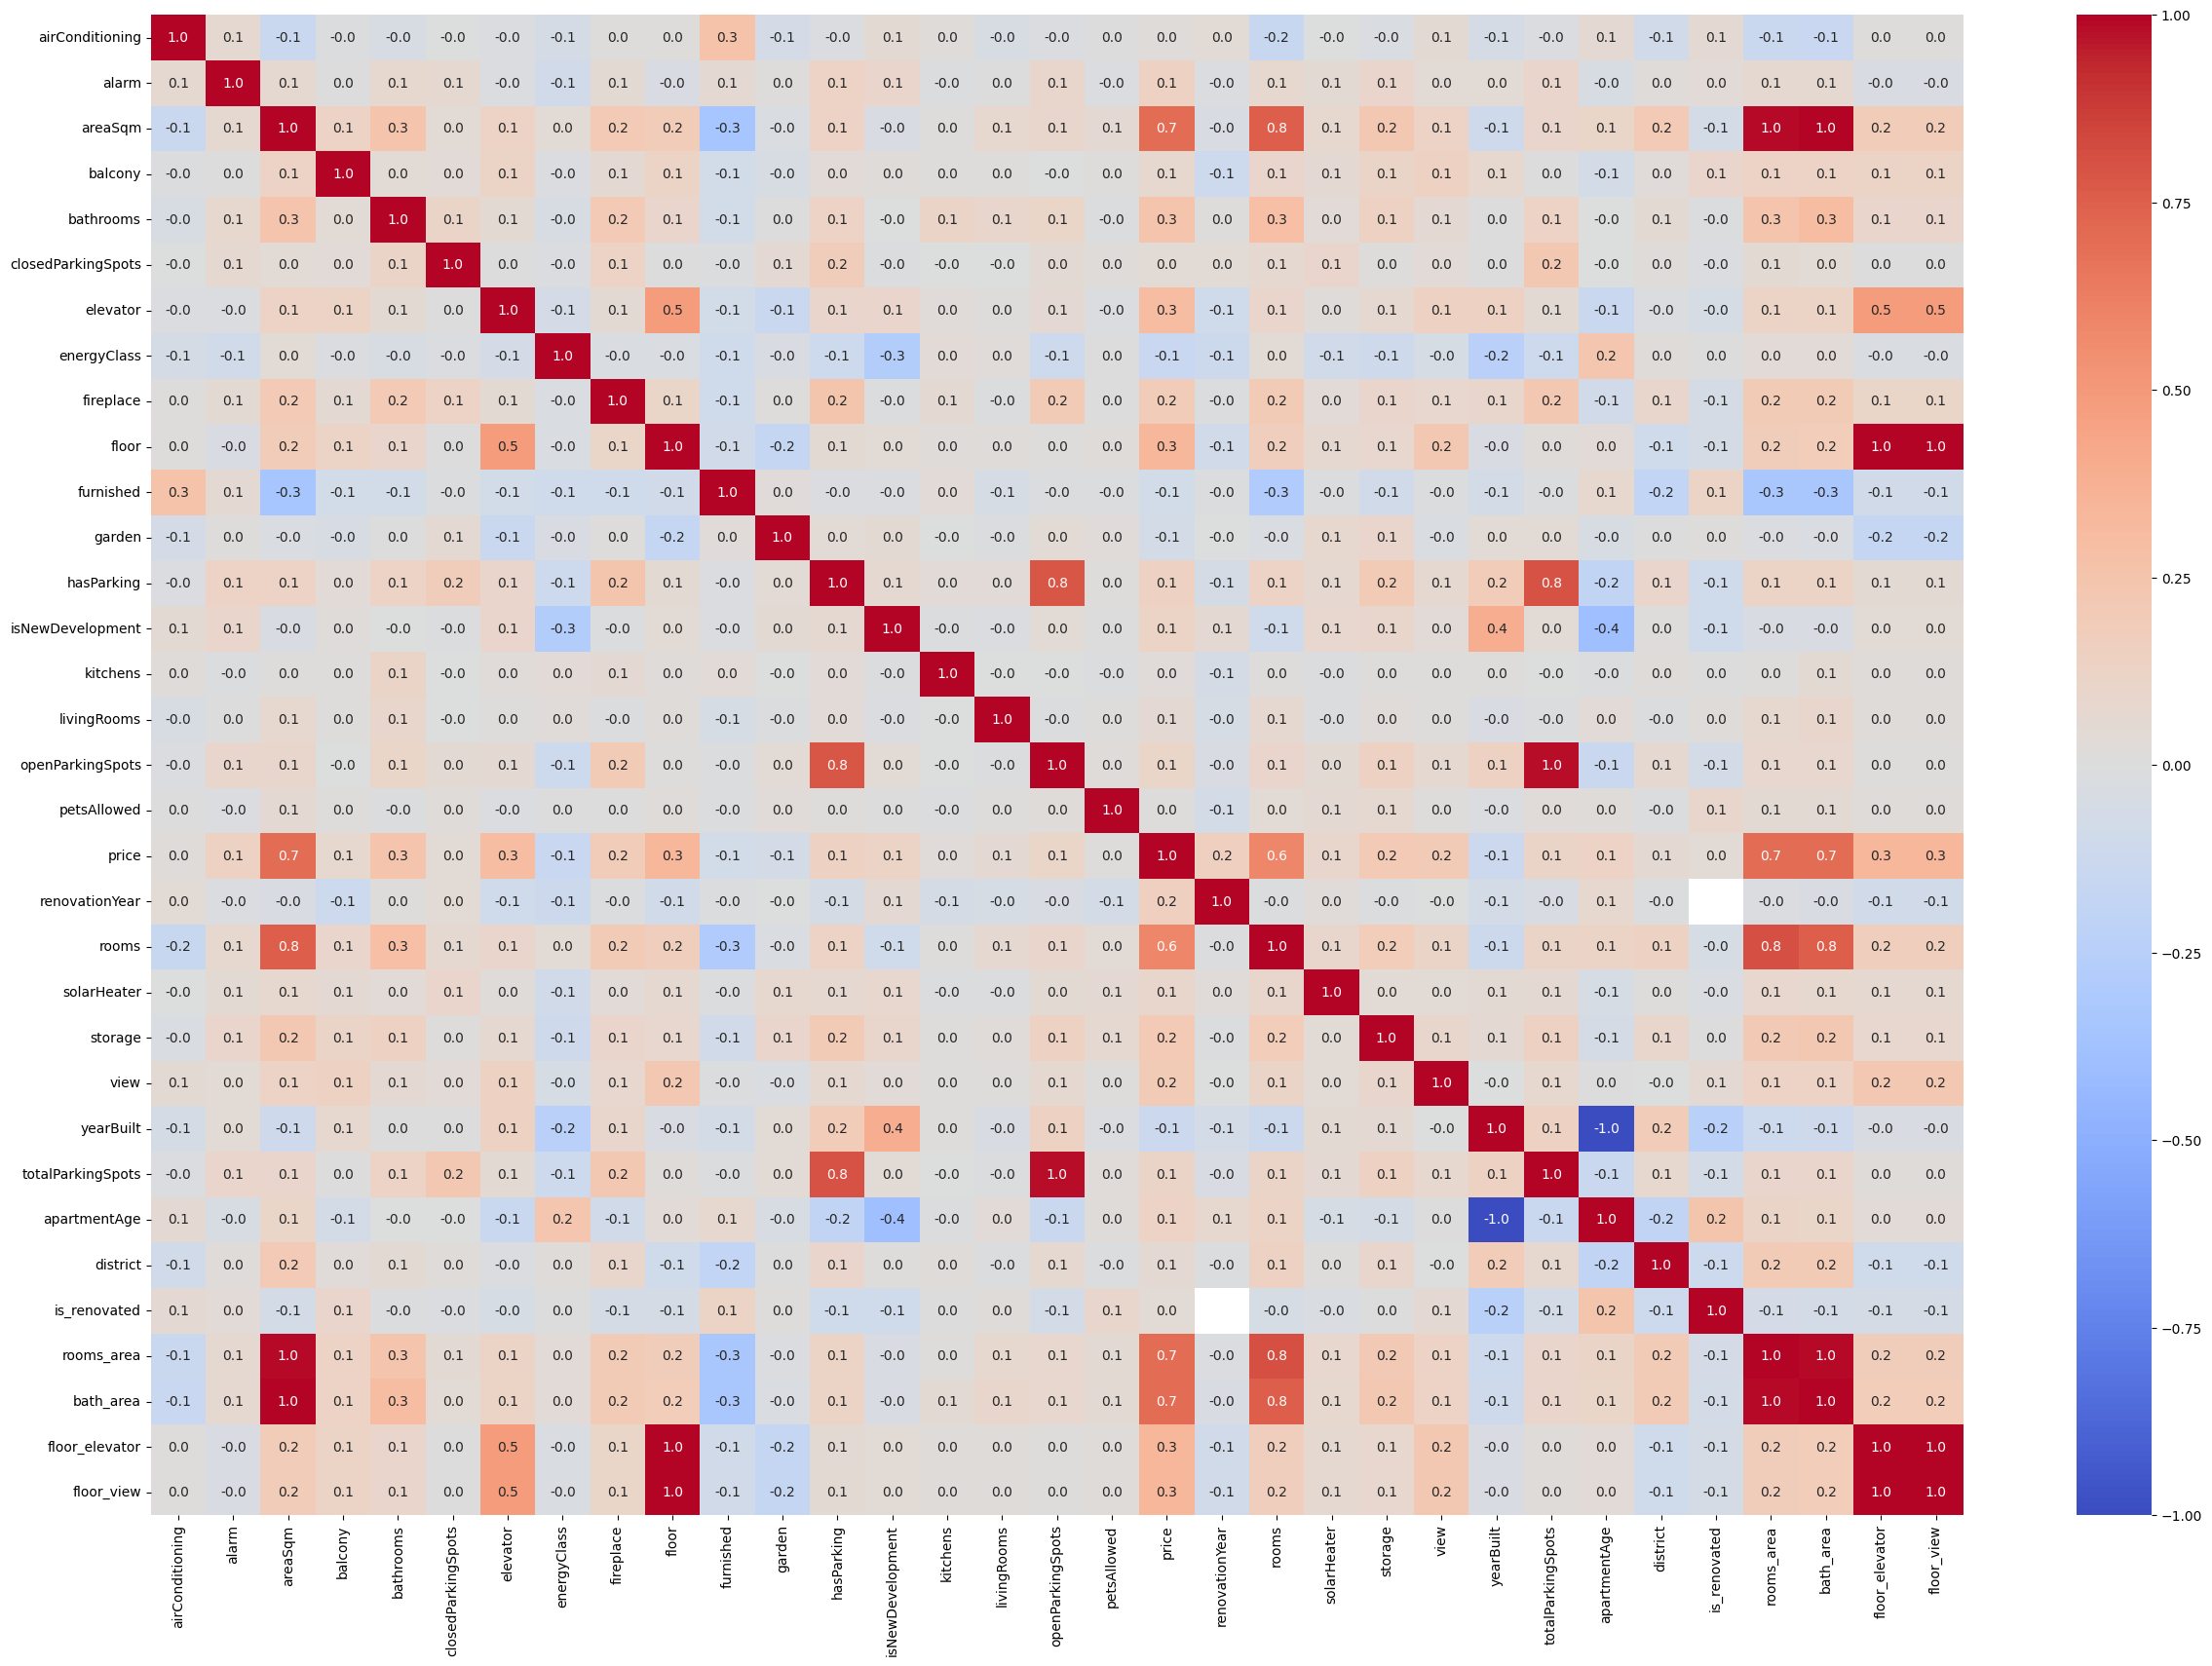

In [4]:
plt.figure(figsize=(30,20))
# Drop 'pool' column from the correlation matrix because it contains only one value
data = df.drop('pool', axis=1)
sns.heatmap(data.corr(method='spearman'), annot=True, cmap='coolwarm', vmin=-1, vmax=1, center=0, fmt='.1f')
plt.show()


### Automated Correlation Detection

Rather than inspecting the entire heatmap manually, we define a helper function `correlation()` that identifies all features whose absolute Spearman correlation with any other feature exceeds a given threshold. We use a threshold of **0.7**, a commonly used rule of thumb: correlations above this level are considered high enough to warrant attention.

The function iterates through the upper triangle of the correlation matrix (to avoid counting each pair twice) and collects the names of features that have at least one correlation exceeding the threshold.


In [5]:
# Find correlated features

def correlation(dataset, threshold):
    col_corr = set()
    corr_matrix = dataset.corr(method='spearman')
    for i in range(len(corr_matrix.columns)):
        for j in range(i):
            if abs(corr_matrix.iloc[i, j]) > threshold:
                colname = corr_matrix.columns[i]
                col_corr.add(colname)
    return col_corr


In [6]:
# Check the highly correlated features (threshold = 0.7)
df_copy = data.drop('price', axis=1)
correlation(df_copy, 0.7)


{'apartmentAge',
 'bath_area',
 'floor_elevator',
 'floor_view',
 'openParkingSpots',
 'rooms',
 'rooms_area',
 'totalParkingSpots'}

**Interpreting the output:** Any features returned by this function are candidates for removal or combination. For example, if `rooms` and `rooms_area` are highly correlated, we might drop `rooms_area` because `rooms` is more interpretable. The decision is documented here for transparency, and the final feature selection is confirmed during the modelling stage.


## Separating Predictors (X) and Target (y)

We now split the DataFrame into:

- **X** (predictors / features): all columns except `price`.
- **y** (target): the `price` column (log-transformed, as applied in the transforms notebook).

This separation is a standard prerequisite for `train_test_split`, which expects X and y as separate arguments.


In [7]:
X = df.drop('price', axis=1)
y = df['price']


## Performing the Three-Way Split

We use scikit-learn's `train_test_split` twice to achieve an 80/10/10 split:

1. **First split (80/20):** We reserve 20% of the data as a temporary hold-out set and assign the remaining 80% to training.
2. **Second split (50/50 of the 20%):** We split the 20% hold-out evenly into validation (10%) and test (10%).

The `random_state=42` parameter ensures **reproducibility** meaning anyone who runs this notebook with the same seed will get the exact same train/val/test partitions. This is critical for debugging and for fair comparison between models.


In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_test, y_test, test_size=0.5, random_state=42)


## Verifying Split Proportions

A quick sanity check confirms that the proportions are as expected: 0.8 for training, 0.1 for validation, and 0.1 for testing. This ensures the splits were applied correctly before we save the files.


In [9]:
for dataset in [y_train, y_val, y_test]:
    print(round(len(dataset)/len(y), 2))


0.8
0.1
0.1


## Saving the Subsets

We save each subset (predictors and target separately) to a `subsets/` directory. This file organisation keeps the pipeline modular: the modelling notebook can load only the subsets it needs, and we avoid re-running the entire preprocessing pipeline every time we experiment with a new model.

The six files produced are:

| File | Content |
|---|---|
| `train_predictors.csv` | Feature matrix for training |
| `train_target.csv` | Target vector for training |
| `val_predictors.csv` | Feature matrix for validation (hyperparameter tuning) |
| `val_target.csv` | Target vector for validation |
| `test_predictors.csv` | Feature matrix for final evaluation |
| `test_target.csv` | Target vector for final evaluation |


In [10]:
X_train.to_csv("subsets/train_predictors.csv", index=False)
X_val.to_csv("subsets/val_predictors.csv", index=False)
X_test.to_csv("subsets/test_predictors.csv", index=False)
y_train.to_csv("subsets/train_target.csv", index=False)
y_val.to_csv("subsets/val_target.csv", index=False)
y_test.to_csv("subsets/test_target.csv", index=False)
